In [1]:
import bw2data as bd
import bw2io as bi
import bw2calc as bc
import bw2analyzer as bwa
import polars as pl 
from tqdm import tqdm

bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")

18:12:28+0200 [warning  ] Can't import `SimaProBlockCSVImporter` - please install `bw2io` with `pip install bw2io[multifunctional]` or install `multifunctional` and `bw_simapro_csv` manually.


In [2]:
gwps = [m for m in bd.methods if "gwp" in str(m).lower() and "no LT" not in str(m) and "EF v3.1" in str(m) and "fossil" not in str(m) and "biogenic" not in str(m) and "land" not in str(m) and "EN15804" not in str(m)]

In [3]:
gwps[0]

('ecoinvent-3.11',
 'EF v3.1',
 'climate change',
 'global warming potential (GWP100)')

In [4]:
bd.databases

Databases dictionary with 11 object(s):
	2026-3-19-11h18_processes_RE2020
	2026-4-21_consumptions_processes
	2026-4-22-15h1_buildings_RE2020
	2026-4-22-16h25_archetypes_RE2020_BB
	2026-4-22-16h7_buildings_cons_RE2020
	2026-4-23-18h10_archetypes_RE2020_PRB
	2026-5-7-20h29_archetypes_RE2020_MIB
	2026-5-7-20h29_bernoulli_RE2020
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	pr_based_arch_alamain

In [2]:
bernoudb = bd.Database("2026-5-7-20h29_bernoulli_RE2020")
archdb = bd.Database("2026-5-7-20h29_archetypes_RE2020_MIB")

In [3]:
a = archdb.random()
a

'Bureau' (m2, FR, None)

In [8]:
import numpy as np
from stats_arrays.distributions.bernoulli import BernoulliUncertainty

@classmethod
def _fixed_random_variables(cls, params, size, seeded_random):
    data = np.zeros((params.shape[0], size))
    mask = (
        seeded_random.random_sample(size * params.shape[0])
        .reshape((params.shape[0], size))
        <= params["loc"].reshape(params.shape[0], 1)  # ← the fix
    )
    data[mask] = 1
    return data

BernoulliUncertainty.random_variables = _fixed_random_variables

In [15]:
lca = bc.LCA(
    demand = {a : 1.0},
    method=gwps[0],
    use_distributions=True
    )
lca.lci()
lca.lcia()



In [24]:
next(lca)  # une seule itération MC
from bw2analyzer import ContributionAnalysis
ca = ContributionAnalysis()
results = ca.annotated_top_processes(lca, limit=20)
for score, _, act in results:
    print(f"{act['name']}: {score:.4f}")

clinker production: 1195.0312
natural gas venting from petroleum/natural gas production: 351.6329
pig iron production: 230.5506
heat production, at hard coal industrial furnace 1-10MW: 135.1256
diesel, burned in building machine: 118.9076
treatment of used refrigerant R134a, venting: 97.2534
hard coal mine operation and hard coal preparation: 85.3932
treatment of waste bitumen sheet, municipal incineration: 79.8610
sweet gas, burned in gas turbine: 79.7717
iron sinter production: 74.8886
treatment of waste plastic, mixture, municipal incineration: 57.9466
electricity production, hard coal: 48.0423
treatment of waste expanded polystyrene, municipal incineration: 44.2570
quicklime production, in pieces, loose: 41.7429
polystyrene production, expandable: 40.9472
transport, freight, light commercial vehicle, fleet average: 40.6398
treatment of waste natural gas, sweet, burned in production flare: 37.2613
electricity production, hard coal: 35.8964
pig iron production: 34.3959
heat pump prod

In [16]:
lca_all = [lca.score for _ in zip(lca, range(30))]
lca_all

[8361.970235267723,
 4730.342656766544,
 6700.513027645309,
 7812.763095416947,
 5249.080317746866,
 10620.644112291819,
 8457.50030915785,
 8081.993717773875,
 5393.829341001514,
 5762.601042027272,
 6612.487426578124,
 4467.742710475338,
 5599.164192651121,
 11951.509784821688,
 6122.101073700049,
 5340.384081427218,
 5322.404418683751,
 7176.462138688112,
 11013.257137274555,
 6423.752186597792,
 6709.315761957512,
 7176.823474750158,
 4467.968946807341,
 8592.410000480591,
 8104.390774513376,
 4485.686117314221,
 5474.77777910583,
 5258.243631116041,
 7204.843007441534,
 6127.249970272214]

In [18]:
import numpy as np
np.median(lca_all)


6518.119806587958

In [47]:
b = bd.Database('2026-4-22-16h25_archetypes_RE2020_BB').search("Bureau")[0]
b

'Bureau' (m2, FR, None)

In [54]:
lca = bc.LCA(
    demand = {b : 1.0},
    method=gwps[0],
    use_distributions=True
    )
lca.lci()
lca.lcia()


In [55]:
lca_all = [lca.score for _ in zip(lca, range(5))]
lca_all

[1253.8707963578208,
 1250.4869977905284,
 1246.2469866371055,
 1248.3777435878255,
 1166.9281505989688]

In [88]:
pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-5-5-16h30_MC_runs/scores.parquet")

iteration,demand,method,score
u32,str,str,f64
0,"""Logement_collectif""","""ecoinvent-3.11 | EF v3.1 | cli…",1381.220089
1,"""Logement_collectif""","""ecoinvent-3.11 | EF v3.1 | cli…",1321.82318
2,"""Logement_collectif""","""ecoinvent-3.11 | EF v3.1 | cli…",1409.180819
3,"""Logement_collectif""","""ecoinvent-3.11 | EF v3.1 | cli…",1271.733094
4,"""Logement_collectif""","""ecoinvent-3.11 | EF v3.1 | cli…",1313.753685
…,…,…,…
995,"""Enseignement_primaire""","""ecoinvent-3.11 | EN15804+A2 - …",1009.126382
996,"""Enseignement_primaire""","""ecoinvent-3.11 | EN15804+A2 - …",1011.252501
997,"""Enseignement_primaire""","""ecoinvent-3.11 | EN15804+A2 - …",1089.306243


In [13]:
bwa.print_recursive_calculation(activity=a,lcia_method=gwps[0])

Fraction of score | Absolute score | Amount | Activity
0001 |  2696 |     1 | 'Bureau' (m2, FR, None)
  0.0126 | 34.08 | 0.8972 | 'bernoulli_bureau_planchers_acier / béton_m²' (m², FR, None)
    0.0126 | 34.08 | 0.445 | 'Planchers_Acier / béton' (m², FR, ('custom_process',))
      0.0109 | 29.31 | 0.09611 | 'market for concrete, normal strength' (cubic meter, RoW, None)
  0.0128 | 34.44 | 0.9743 | 'bernoulli_bureau_revêtements de voirie_pierre naturelle_m²' (m², FR, None)
    0.0128 | 34.44 | 0.1763 | 'Revêtements de voirie_Pierre naturelle' (m², FR, ('custom_process',))
      0.0125 | 33.79 | 35.26 | 'market for natural stone plate, polished' (kilogram, GLO, None)
  0.0118 |  31.8 | 0.849 | 'bernoulli_bureau_dalles et prédalles_béton plein armé_m³' (m³, FR, None)
    0.0118 |  31.8 | 0.05586 | 'Dalles et prédalles_Béton plein armé' (m³, FR, ('custom_process',))
  0.013 | 34.97 | 0.9347 | 'bernoulli_bureau_services_fluides frigorigènes_kg' (kilogram, FR, None)
    0.013 | 34.97 | 0.014

In [57]:
import pandas as pd
df_intensites_consos = pd.read_excel("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-5-7-16h20_intensites_consos_RE2020.xlsx")

In [64]:
import seaborn as sns

In [78]:
df_intensites_consos[df_intensites_consos["usage"]=="Logement collectif"]

,usage,target_len,produit,quant_surf,param_bernoulli,shape,loc,scale
4,Logement collectif,1131,cons_eau_tout,"[2.3008849557522124, 2.198473282442748, 2.2622...",1,2.516487e-01,0.0,2.110495
9,Logement collectif,1131,cef_bois_ch,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",1,4.328054e-01,0.0,45.896512
14,Logement collectif,1131,cef_bois_ecs,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, ...",1,2.342251e-01,0.0,26.945515
19,Logement collectif,1131,cef_elec_ch,"[13.4, 13.7, 12.5, 15.0, 13.5, 9.3, 6.5, 2.8, ...",1,1.782124e+00,0.0,2.503559
24,Logement collectif,1131,cef_elec_depl,"[0.4, 0.4, 0.4, 0.4, 0.4, 0.0, 0.0, 0.9, 3.6, ...",1,9.127198e-01,0.0,1.800077
29,Logement collectif,1131,cef_elec_dist,"[0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.0, 0.2, 0.0, ...",1,1.002785e+00,0.0,0.401056
34,Logement collectif,1131,cef_elec_ecl,"[1.8, 1.9, 2.0, 1.9, 2.0, 1.5, 1.5, 1.8, 1.8, ...",1,9.622546e-02,0.0,1.921581
39,Logement collectif,1131,cef_elec_ecs,"[8.1, 7.0, 6.5, 7.9, 6.5, 9.3, 13.2, 0.3, 6.3,...",1,1.815890e+00,0.0,2.099835
44,Logement collectif,1131,cef_elec_fr,"[8.4, 7.0, 5.8, 8.3, 5.3, 0.0, 1.6, 3.1, 5.0, ...",1,9.478568e-01,0.0,1.217665
49,Logement collectif,1131,cef_elec_mobi,"[24.8, 24.8, 24.8, 24.8, 24.8, 24.8, 24.8, 24....",1,5.365942e-03,0.0,24.814759


<Axes: ylabel='Count'>

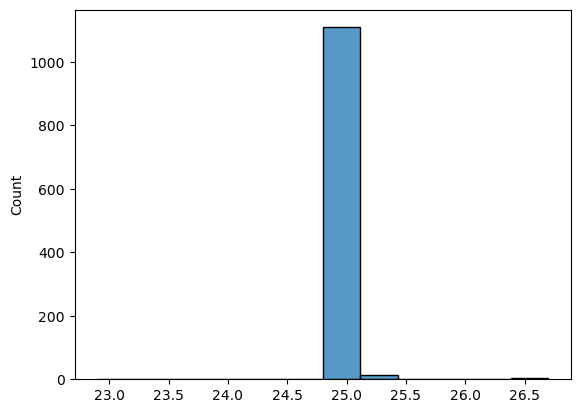

In [84]:
sns.histplot(eval(df_intensites_consos[df_intensites_consos["usage"]=="Logement collectif"]["quant_surf"].to_list()[9]))

In [5]:
bernoudb = bd.Database('2026-5-7-20h29_bernoulli_RE2020')

In [16]:
[b for b in bernoudb]

['bernoulli_bureau_réseaux d'évacuation et d'assainissement (eaux pluviales et eaux usées)_pvc_m' (meter, FR, None),
 'bernoulli_logement collectif_isolation_membranes/pare-vapeur_m²' (m², FR, None),
 'bernoulli_logement collectif_voirie / réseaux divers (y compris réseaux intérieurs) et aménagements extérieurs de la parcelle_divers_m²' (m², FR, None),
 'bernoulli_maison individuelle ou accolée_système pour murs (iti)_laine de verre_m²' (m², FR, None),
 'bernoulli_maison individuelle ou accolée_services_fluides frigorigènes_kg' (kilogram, FR, None),
 'bernoulli_bureau_gardes corps_béton armé_m' (meter, FR, None),
 'bernoulli_maison individuelle ou accolée_couverture / étanchéité_divers_m³' (m³, FR, None),
 'bernoulli_enseignement secondaire (partie jour)_menuiseries intérieures et extérieures / fermetures_divers_m²' (m², FR, None),
 'bernoulli_bureau_produits de préparation et réparation_egalisation des surfaces (lissage/ragréage/planéité)_m²' (m², FR, None),
 'bernoulli_enseignement p

In [18]:
[e for e in list(a.edges()) if "bernoulli_Consommations_gaz" in str(e)]

[]

In [23]:
from archetypes_re2020.archetypes.intensities_based_archetypes_db import *
import pandas as pd


In [25]:
df_intensites_consos = pd.read_excel("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/2026-5-7-16h20_intensites_consos_RE2020.xlsx")

In [38]:
any([math.isnan(a) for a in df_intensites_consos["param_bernoulli"]])

False

In [30]:
[a for a in arch_db]

['Logement_collectif' (m2, FR, None),
 'Maison_individuelle_ou_accolée' (m2, FR, None),
 'Enseignement_primaire' (m2, FR, None),
 'Enseignement_secondaire_(partie_jour)' (m2, FR, None),
 'Bureau' (m2, FR, None)]

In [49]:
def create_bernoulli_edge(node, input_node, bernoulli_param):
    """
    Crée un échange avec distribution de Bernoulli.
    
    Note: stats_array utilise loc = 1-p (Wikipedia utilise p).

    Args:
        node: Nœud brightway source.
        input_node: Nœud brightway destination.
        bernoulli_param (float): Paramètre p de Bernoulli.

    Returns:
        Edge: Échange créé et sauvegardé.
    """
    if 1-bernoulli_param == 0 :
        #Si le paramètre vaut 1, c'est que tout le monde est concerné, donc pas d'incertitude, valeur 1
        edge = node.new_edge(
            input=input_node,
            unit=input_node['unit'],
            database=input_node['database'],
            amount=1,
            type="technosphere"
        )
        edge.save()
    
    else : 
        edge = node.new_edge(
            input=input_node,
            unit=input_node['unit'],
            database=input_node['database'],
            amount=1 - bernoulli_param,
            type="technosphere"
        )
        edge['uncertainty type'] = UNCERTAINTY_TYPES["BERNOULLI"]
        edge['loc'] = 1 - bernoulli_param  # Conversion Wikipedia -> stats_array
        edge['minimum'] = 0
        edge['maximum'] = 1
        edge.save()
    return edge

def add_exchanges_to_archetypes_consumptions(df, conso_db, archetype_db_name, bernoulli_db_name):
    """
    Ajoute les échanges aux archétypes depuis les données d'intensités matières.

    Args:
        df (pd.DataFrame): DataFrame avec les intensités consos.
        conso_db (bd.Database): Base de données des de consommations RE2020.
        archetype_db_name (str): Nom de la base d'archétypes.
        bernoulli_db_name (str): Nom de la base Bernoulli.
    """
    cons_codes_dict = get_consumptions_codes(conso_db)

    for i in tqdm(df.index, desc="Ajout des échanges aux archétypes"):
        shape = df.at[i, 'shape']
        loc   = df.at[i, 'loc']
        scale = df.at[i, 'scale']
        if any([math.isnan(p) for p in [shape, loc, scale]]):
            continue
        
        conso_name = df.at[i, 'produit'].split("_")
        
        vecteur = conso_name[1]
        destination = conso_name[2]

        prod_code = cons_codes_dict[vecteur]
        # print(prod_code)
        prod_node = bd.get_activity(prod_code)

        usage = df.at[i, 'usage']
        bernoulli_param = df.at[i, 'param_bernoulli']
        
        # Récupération des nœuds
        archetype_node = bd.get_activity((archetype_db_name, str(usage).lower().replace(' ', "_")))
        # print(archetype_node)
        # bernoulli_node = bd.get_activity((bernoulli_db_name, cons_codes_dict[vecteur][1]))
        bernoulli_node = bd.get_node(
            database = bernoulli_db_name,
            code_prod_db = "_".join([usage, prod_node["code"],destination])
            )
        # print(bernoulli_node)
        # Création de l'échange avec distribution de Bernoulli
        create_bernoulli_edge(archetype_node, bernoulli_node, bernoulli_param)


In [51]:
[len(a.edges()) for a in arch_db]

[326, 296, 361, 362, 346]

In [50]:
add_exchanges_to_archetypes_consumptions(
    df=df_intensites_consos,
    conso_db=bd.Database("2026-4-21_consumptions_processes"),
    archetype_db_name="2026-5-7-20h29_archetypes_RE2020_MIB",
    bernoulli_db_name = '2026-5-7-20h29_bernoulli_RE2020'
    )

Ajout des échanges aux archétypes:   0%|          | 0/85 [00:00<?, ?it/s]

Ajout des échanges aux archétypes: 100%|██████████| 85/85 [00:03<00:00, 22.21it/s]


In [ ]:
def fix_bernoulli_edges(arch_db_name):
    """
    Removes 'minimum' and 'maximum' fields from all Bernoulli edges in the database.
    """
    arch_db = bd.Database(arch_db_name)
    fixed = 0
    for node in tqdm(arch_db, desc="Fixing Bernoulli edges"):
        for edge in node.exchanges():
            if edge.get('uncertainty type') == UNCERTAINTY_TYPES["BERNOULLI"]:
                changed = False
                for field in ('minimum', 'maximum'):
                    if field in edge._data:
                        del edge._data[field]
                        changed = True
                if changed:
                    edge.save()
                    fixed += 1
    print(f"Fixed {fixed} Bernoulli edges.")

In [54]:
fix_bernoulli_edges('2026-5-7-20h29_archetypes_RE2020_MIB')

Fixing Bernoulli edges: 100%|██████████| 5/5 [00:37<00:00,  7.43s/it]

Fixed 1610 Bernoulli edges.


In [55]:
a= arch_db.random()

In [ ]:
a

In [60]:
[e for e in a.technosphere()][3].as_dict()

{'output': ('2026-5-7-20h29_archetypes_RE2020_MIB',
  'maison_individuelle_ou_accolée'),
 'input': ('2026-5-7-20h29_bernoulli_RE2020',
  'isolation_membranes/pare-vapeur_m²_30'),
 'unit': 'm²',
 'database': '2026-5-7-20h29_bernoulli_RE2020',
 'amount': 0.9015214241357897,
 'type': 'technosphere',
 'uncertainty type': 6,
 'loc': 0.9015214241357897}

In [11]:
list(b.edges())

[Exchange: 16.97651170591627 kilowatt hour 'Consommations_gaz' (kilowatt hour, FR, ('custom_process',)) to 'cef_gaz_ecs' (kilowatt hour, FR, None),
 Exchange: 1.0 kilowatt hour 'cef_gaz_ecs' (kilowatt hour, FR, None) to 'cef_gaz_ecs' (kilowatt hour, FR, None)]

In [ ]:
[312, 281, 330, 345, 347]

[]

In [15]:
p = prod_db.random()

In [17]:
a = prod_db.get('isolants thermiques et acoustiques pour toitures terrasses_polyuréthane_m²_50')

In [18]:
a

'Isolants thermiques et acoustiques pour toitures terrasses_Polyuréthane' (m², FR, ('custom_process',))

In [16]:
p["code"]

'isolants thermiques et acoustiques pour toitures terrasses_polyuréthane_m²_50'

In [6]:
"cef_elec_ch".split("_")

['cef', 'elec', 'ch']

In [19]:
len(prod_db)

367

In [23]:
len(set([p["code"] for p in prod_db]))

367

In [17]:
df = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-5-5-20h1_MC_runs/scores.parquet")
df

iteration,demand,indicator,score
u32,str,str,f64
0,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",690.328378
1,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",573.632367
2,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",781.955657
3,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",440.142244
4,"""Modules photovoltaïques_Silici…","""ecoinvent-3.11 | EF v3.1 | cli…",784.712585
…,…,…,…
995,"""Planchers_Acier / béton""","""ecoinvent-3.11 | EF v3.1 | cli…",74.300773
996,"""Planchers_Acier / béton""","""ecoinvent-3.11 | EF v3.1 | cli…",65.81544
997,"""Planchers_Acier / béton""","""ecoinvent-3.11 | EF v3.1 | cli…",65.273214


In [ ]:
from cmcrameri import cm
import seaborn as sns;

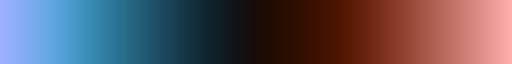

In [12]:
cmap = cm.berlin
cmap

/tmp/ipykernel_101006/2839641563.py:1: UserWarning: Ignoring `palette` because no `hue` variable has been assigned.
  sns.histplot([0,0,0,0,1,1,2,3],palette= 3)


<Axes: ylabel='Count'>

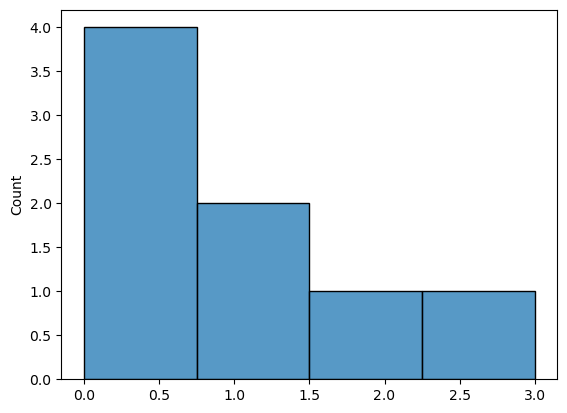

In [14]:
sns.histplot([0,0,0,0,1,1,2,3],palette= 3)

In [6]:
bd.databases

Databases dictionary with 9 object(s):
	2026-3-19-11h18_processes_RE2020
	2026-4-21_consumptions_processes
	2026-4-22-15h1_buildings_RE2020
	2026-4-22-16h25_archetypes_RE2020_BB
	2026-4-22-16h7_buildings_cons_RE2020
	2026-4-23-18h10_archetypes_RE2020_PRB
	ecoinvent-3.11-biosphere
	ecoinvent-3.11-cutoff
	pr_based_arch_alamain

In [7]:
gwps = [m for m in bd.methods if "gwp" in str(m).lower() and "no LT" not in str(m) and "EF v3.1" in str(m) and "fossil" not in str(m) and "biogenic" not in str(m) and "land" not in str(m)]
gwps

[('ecoinvent-3.11',
  'EF v3.1',
  'climate change',
  'global warming potential (GWP100)'),
 ('ecoinvent-3.11',
  'EN15804+A2 - Core impact categories and indicators',
  'climate change: total (EF v3.1 - IPCC 2021)',
  'global warming potential (GWP100)')]

In [27]:
build_db = bd.Database("2026-4-22-16h7_buildings_cons_RE2020")
cons_db = bd.Database("2026-4-21_consumptions_processes")

In [13]:
b=build_db.random()

In [48]:
c = [c for c in cons_db if ("consommations_réseau_autres" in str(c["name"]).lower())][0]
c

'Consommations_réseau_autres' (kilowatt hour, FR, ('custom_process',))

In [50]:
for e in c.technosphere() :
    e["amount"] = 3.6
    e.save()
    print(e["amount"])

3.6


In [51]:
list(c.edges())

[Exchange: 1 kilowatt hour 'Consommations_réseau_autres' (kilowatt hour, FR, ('custom_process',)) to 'Consommations_réseau_autres' (kilowatt hour, FR, ('custom_process',)),
 Exchange: 3.6 megajoule 'heat and power co-generation, biogas, gas engine' (megajoule, FR, None) to 'Consommations_réseau_autres' (kilowatt hour, FR, ('custom_process',))]

In [14]:
b.as_dict()

{'name': '605809_1',
 'usage': 'Maison individuelle ou accolée',
 'unit': 'm2',
 'location': 'FR',
 'database': '2026-4-22-16h7_buildings_cons_RE2020',
 'code': '605809_1',
 'type': 'processwithreferenceproduct',
 'id': 305345122134220800}

In [52]:
gwps[0]

('ecoinvent-3.11',
 'EF v3.1',
 'climate change',
 'global warming potential (GWP100)')

In [24]:
b =[p for p in build_db if ("logement" in str(p["usage"]).lower())][0]

In [25]:
b

'346210_1' (m2, FR, None)

In [8]:
arch_db = bd.Database("2026-4-22-16h25_archetypes_RE2020_BB")

In [9]:
a = arch_db.search("logement")[0]
a

'Logement_collectif' (m2, FR, None)

In [26]:
list(b.edges())

[Exchange: 1.0 m2 '346210_1' (m2, FR, None) to '346210_1' (m2, FR, None),
 Exchange: 0.011759863585582406 meter 'Réseaux d'adduction du gaz_Polyéthylène' (meter, FR, ('custom_process',)) to '346210_1' (m2, FR, None),
 Exchange: 0.011759863585582406 meter 'Gaines / fourreaux_PVC' (meter, FR, ('custom_process',)) to '346210_1' (m2, FR, None),
 Exchange: 0.0009801846298582936 unité 'Voirie / réseaux divers (y compris réseaux intérieurs) et aménagements extérieurs de la parcelle_Divers' (unité, FR, ('custom_process',)) to '346210_1' (m2, FR, None),
 Exchange: 0.029399658963956018 meter 'Réseaux d'évacuation et d'assainissement (eaux pluviales et eaux usées)_PVC' (meter, FR, ('custom_process',)) to '346210_1' (m2, FR, None),
 Exchange: 0.005879931792791203 unité 'Réseaux d'évacuation et d'assainissement (eaux pluviales et eaux usées)_Béton' (unité, FR, ('custom_process',)) to '346210_1' (m2, FR, None),
 Exchange: 0.011759863585582406 meter 'Gaines / fourreaux_Polyéthylène' (meter, FR, ('cus

In [33]:
processes_list = [a for a in arch_db]
indicators_list = gwps

In [45]:
demands = {str(p["name"]) :{p["id"] : 1.0} for p in processes_list}
# method_config = bc.MethodConfig(impact_categories=indicators_list)
data_objs = bd.get_multilca_data_objs(demands, method_config = {"impact_categories" : indicators_list})

mlca = bc.MultiLCA(
    demands=demands,
    method_config={"impact_categories" : indicators_list},
    data_objs=data_objs,
    use_distributions=True,
    # seed_override=seed,
)
mlca.lci()
mlca.lcia()

In [41]:
# Première itération : on récupère les keys et la taille de la biosphère
score_keys   = list(mlca.scores.keys())                  # (method, demand)
demand_keys  = list(mlca.inventories.keys())             # demand names
n_bio        = mlca.biosphere_matrix.shape[0]

In [44]:
n_bio

3238

In [15]:
lca = bc.LCA(demand={a:1.0},method = gwps[0],use_distributions=True)
lca.lci()
lca.lcia()

In [20]:
next(lca)

In [21]:
l = lca.characterized_inventory

In [22]:
print(l)

<Compressed Sparse Row sparse matrix of dtype 'float64'
	with 21483 stored elements and shape (3238, 105436)>
  Coords	Values
  (50, 5)	2.4946178156797663e-07
  (50, 11)	8.346442862151354e-05
  (50, 12)	0.0021052687324601893
  (50, 22)	6.36293706808866e-08
  (50, 50)	1.7922143902398954e-05
  (50, 54)	0.007961133008932282
  (50, 70)	5.3166987543684966e-08
  (50, 92)	0.0006505957762476198
  (50, 105)	0.028423212531083302
  (50, 158)	0.0007967443110294272
  (50, 168)	9.659594846220643e-21
  (50, 185)	0.0012207148467899313
  (50, 213)	0.0001472698972260636
  (50, 248)	4.430396446524992e-05
  (50, 252)	0.00021722946034408841
  (50, 255)	2.179023516497759e-08
  (50, 261)	3.2999070120053185e-06
  (50, 274)	5.817071901095781e-05
  (50, 300)	1.329207534630766e-07
  (50, 304)	0.0008855104020162339
  (50, 308)	0.045608014763209824
  (50, 310)	0.02678784062725086
  (50, 329)	9.90396062851562e-06
  (50, 347)	0.0006487090848931622
  (50, 421)	7.043799011055338e-08
  :	:
  (3214, 13300)	0.05122327017

In [27]:
from bw2calc import PYPARDISO
print(PYPARDISO)  # must be True

True


In [26]:
from bw2analyzer.report import SerializedLCAReport

ImportError: cannot import name 'GraphTraversal' from 'bw2calc' (/home/thibault.chevilliet@enpc.fr/miniconda3/envs/bw25_clean/lib/python3.13/site-packages/bw2calc/__init__.py)

In [32]:
lca.biosphere_matrix.shape[0]

3238

In [1]:
import polars as pl

In [9]:
df_score = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-4-30-17h25_MC_runs/scores.parquet")

In [20]:
df_score

iteration,demand,method,score
u32,str,str,f64
0,"""Enseignement_secondaire_(parti…","""ecoinvent-3.11 | EF v3.1 | cli…",1806.879064
1,"""Enseignement_secondaire_(parti…","""ecoinvent-3.11 | EF v3.1 | cli…",1971.100342
2,"""Enseignement_secondaire_(parti…","""ecoinvent-3.11 | EF v3.1 | cli…",2141.004087
3,"""Enseignement_secondaire_(parti…","""ecoinvent-3.11 | EF v3.1 | cli…",1823.748609
4,"""Enseignement_secondaire_(parti…","""ecoinvent-3.11 | EF v3.1 | cli…",2007.12236
…,…,…,…
995,"""Enseignement_primaire""","""ecoinvent-3.11 | EN15804+A2 - …",940.181197
996,"""Enseignement_primaire""","""ecoinvent-3.11 | EN15804+A2 - …",943.33754
997,"""Enseignement_primaire""","""ecoinvent-3.11 | EN15804+A2 - …",866.372967


In [26]:


def plot_scores_delta(df_scores,arch1,arch2,indicator,output_dir):
    indicator_str = " | ".join(eval(indicator))
    scores1 = df_scores.filter(
        pl.col("demand")== arch1["name"],
        pl.col("method") == indicator_str
        )["score"].to_list()
    scores2 = df_scores.filter(
        pl.col("demand")== arch2["name"],
        pl.col("method") == indicator_str
        )["score"].to_list()
    
    today = datetime.today()
    horodatage = f"{today.year}-{today.month}-{today.day}-{today.hour}h{today.minute}"
    res = [s1 - s2 for s1,s2 in zip(scores1,scores2)]
    fig, ax = plt.subplots()

    sns.histplot(res, element="step",ax = ax)


    fig.savefig(f"{output_dir}/{horodatage}_{arch1["name"]}-{arch2["name"]}_distrib.pdf",dpi = 300)

    print(f"Figure saved in {output_dir}")

    return fig, scores1, scores2, res

Figure saved in /home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/reports/figures/Distributions


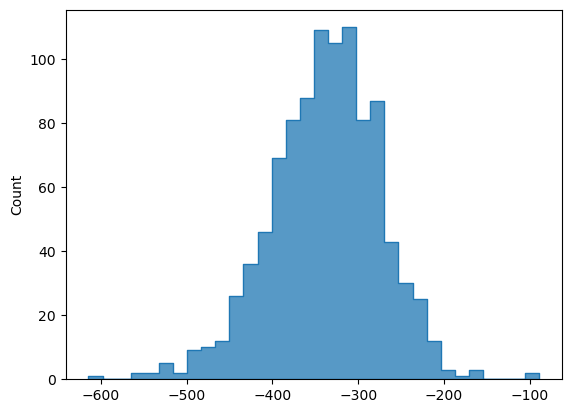

In [30]:
from archetypes_re2020.config import FIGURES_DIR
from datetime import datetime
import matplotlib.pyplot as plt
import seaborn as sns

df_scores = pl.read_parquet("/home/thibault.chevilliet@enpc.fr/Documents/2601_archetypes_re2020/data/processed/MC_runs/2026-4-30-17h25_MC_runs/scores.parquet")
bd.projects.set_current("2026-01-13-ecoinvent-3.11-cutoff")
arch_db = bd.Database("2026-4-22-16h25_archetypes_RE2020_BB")

indicators = [m for m in bd.methods if "gwp" in str(m).lower() and "no LT" not in str(m) and "EF v3.1" in str(m) and "fossil" not in str(m) and "biogenic" not in str(m) and "land" not in str(m)]

indicator = str(indicators[0])

output_dir = FIGURES_DIR/"Distributions" 
arch1 = arch_db.search("Maison")[0]
arch2 = arch_db.search("Bureau")[0]
f, s1, s2, delta = plot_scores_delta(df_scores,arch1,arch2,indicator,output_dir)

In [12]:
scores1 = df_scores.filter(
    pl.col("demand")== arch1["name"],
    pl.col("method") == indicator
    )["score"].to_list()

In [23]:
" | ".join(eval(indicator))

'ecoinvent-3.11 | EF v3.1 | climate change | global warming potential (GWP100)'

In [21]:
df_scores.filter(pl.col("demand")==arch1['name'])["method"][0]

'ecoinvent-3.11 | EF v3.1 | climate change | global warming potential (GWP100)'

In [31]:
s2

[1558.8376626600482,
 1632.7482570506427,
 1805.9916734071749,
 1633.3001239941898,
 1698.908470128811,
 1712.0010490375198,
 1672.3944280210212,
 1701.875674945652,
 1640.6562248558985,
 1585.2084661202973,
 1634.148610073285,
 1615.4042652940188,
 1669.6814879574417,
 1632.8617651206137,
 1631.4625413176975,
 1592.7085423244218,
 1632.2737806223327,
 1539.7687431602178,
 1653.2299884281201,
 1565.0733428049068,
 1729.0298259705792,
 1488.4096430618772,
 1591.2376520823702,
 1548.1652779599906,
 1561.6394091064767,
 1928.423335710569,
 1600.988640875757,
 1533.6067289579269,
 1686.599035704892,
 1783.4998804077945,
 1643.1070725431246,
 1594.194794016018,
 1735.2280117303924,
 1765.047460103884,
 1678.7290256579333,
 1681.8965239510153,
 1625.6267149842154,
 1692.6945550157805,
 1715.8551705279256,
 1710.3124664531638,
 1657.2170289426165,
 1762.9931611744978,
 1583.458665395667,
 1698.7835751085624,
 1551.8568266948178,
 1612.9928203878867,
 1688.7357766196283,
 1599.8785385581582,
 

In [2]:
a = (1,2,3)

In [3]:
a[1:]

(2, 3)

In [4]:
arch_db

NameError: name 'arch_db' is not defined